# Case Study 12 — Collections as Resource Allocation: Roll Rates, Vintage Curves, Survival Analysis and Bucket-Wise PD for Tele-Calling

**Priority:** ★★★ Must-visit · **Reference:** Case Study 12 — *Navi: Personal-Loan Underwriting and Bucket-Wise Collections Scorecards* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Collections, Chief Risk Officer, CFO (credit cost), Head of Credit Policy
**Data:** ⚠️ **SYNTHETIC** (D-12-01). Loan-level repayment data is confidential; this is a calibrated simulation, not Navi's.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs12_collections_bucket_scorecards.ipynb`

## 0. Executive Summary for Business

*(Synthetic loan book calibrated to Navi's documented portfolio; written after the analysis.)*

- **The problem:** tele-callers can reach only about 45% of customers who are 30–89 days late. Today they call the **oldest delinquencies first**, which sends effort to accounts that are often already lost.
- **Calls work, and we proved it causally:** a 6-month randomised pilot showed a call raises the chance a 30–59-day-late customer becomes current by **+5.9 points** (24.3% vs 18.4%, p = 0.0003) and a 60–89-day customer by **+4.6 points** (p = 0.002).
- **Smarter allocation pays:** calling the customers where a call saves the most ₹ (call effect × default risk × outstanding) avoids **91% more credit loss** than oldest-first at the *same* capacity (95% CI of the gain excludes zero). That is **≈ ₹5.5 crore a year per 10 lakh loans** (range ₹2.4–9.8 crore).
- **Book health:** about 2.3% of current loans slip each month; once 60–89 days late, 70% roll to 90+. **Collection efficiency is 96.6%**, in line with Navi's documented 96.63%. The mid-2024 credit tightening cut early defaults by about 25% (hazard ratio 0.75), but **entirely through better bureau scores**: once borrower mix is controlled, there is no extra effect.
- **Cohorts:** small-ticket, low-bureau loans sourced through **partner/DSA channels lose money** (−3.4% of principal) because acquisition cost and losses outweigh the higher yield. Organic-app cohorts earn 6–11%.
- **A caution:** predicting *which* delinquent customer rolls forward is hard with origination data alone (out-of-time AUC 0.65, KS 21, below our KS ≥ 25 target). The model is good enough to rank calls, but behavioural data (contact history, promise-to-pay) is the next investment.
- **I recommend:** switch tele-calling to value-based allocation, keep 10% of calls randomised to keep measuring the effect, and stop or reprice partner-sourced small-ticket, low-score lending.

## 1. The Problem in Simple English

A digital lender has lakhs of small personal loans: ₹60,000 for a wedding, a phone, a medical bill. Most customers pay every month. Each month a few miss an EMI. Some of those simply forgot and pay next week. Others are in real trouble, and every month of silence makes recovery less likely: a loan 30 days late is far more likely to come back than one 85 days late.

The lender has three tools, each with a cost:
- **Digital nudges** (SMS, app notifications, WhatsApp): almost free, used for everyone 1–29 days late.
- **Tele-callers**: about 100+ people, each able to make a limited number of calls. They are used for 30–89 days late, but **cannot reach everyone**.
- **Field agents and skip tracing**: expensive, used after 90 days.

Today, tele-callers work the **oldest delinquencies first**. That sounds sensible but may waste calls on accounts that are already lost, while customers who would come back with one conversation slip into default. **Collections is a resource-allocation problem**, as the reference file notes: expensive human effort should go where it changes the outcome and protects the most money.

This notebook answers:
1. How do loans flow between delinquency buckets (**roll rates**), and is that flow stable?
2. Did the mid-2024 credit-policy tightening produce better loans (**vintage and survival analysis**)?
3. Which customer cohorts make or lose money?
4. Can a **within-bucket default-probability model**, plus the measured effect of a call, allocate tele-callers better than "oldest first"? What is that worth in ₹?

## 2. Reference from the Case File

### (a) What Navi did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | Many Indians have "low or no credit history". Small-ticket loans are uneconomic to underwrite manually, "and delinquent accounts must be routed to the right collection channel". |
| Question | "Should this applicant be approved, and at what price? For a delinquent borrower, how likely are they to default, and which channel should work the account?" |
| Data | Application/KYC, device (with consent), bureau; "2.64 million repayment events as of December 31, 2021"; "more than 400 variables" |
| Approach | Underwriting on repayment capacity; "A **cohort-based approach** segments customers by yield, risk, ticket size and acquisition cost"; "**Collections** use payment-behaviour scorecards by delinquency bucket" |
| Collections policy | **0–29 DPD: digital nudges · PAR 30–89: 100+ tele-callers + default-probability algorithms · PAR > 90: field agencies + skip tracing** |
| ML | "customer-wise default probability prediction algorithms" for the PAR 30–89 bucket; algorithms, KS/Gini ND |
| Impact | "Collection efficiency **96.63%** till December 31, 2021"; "over **85%** had CIBIL credit scores greater than 725"; processing time "about a month to just a few milliseconds" |

**Sources:** Navi Finserv DRHP (18 Apr 2022, pp. 125–131) — https://www.bseindia.com/corporates/download/12417/IPO/Navi%20Finserv%20Limited%20%20Draft%20Prospectus_April182022_20220418230940.pdf · Navi Medium blog (30 May 2021) — https://medium.com/navi-technologies/big-impact-with-big-data-navi-using-data-science-to-transform-lending-7cd29a1c22f2

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 60,000 personal loans, 12 monthly vintages (2024), monthly performance to Dec 2025 (≈ 780k loan-months); bureau-score mix calibrated so ≈ 87% exceed 725 |
| Collections | Digital nudges for 1–29 DPD; tele-calling for 30–89 DPD at 45% capacity, **oldest-bucket-first** policy; a **6-month randomised calling pilot (Apr–Sep 2025)** that lets us measure the causal effect of a call |
| Statistics added | Markov roll-rate matrix with an Anderson–Goodman LR stationarity test; vintage curves; Kaplan–Meier + log-rank + Cox proportional hazards; cohort unit economics with chi-square / Kruskal–Wallis; bucket PD logistic model (KS, AUC, calibration, out-of-time); pilot two-proportion tests and an interaction model; allocation simulation |
| Business | Collection efficiency on current demand; ₹ credit loss avoided by value-based call allocation |

### (c) How the industry uses this

Every Indian NBFC and bank collections team runs roll-rate and vintage dashboards monthly (they feed Ind AS 109 expected-credit-loss staging). Bucket-wise "behaviour scores" decide which accounts tele-callers, bots and field agents work (Navi, Kissht in Case 14, and the vendors in Case 19). Survival models are increasingly used for lifetime-PD under Ind AS 109.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | How should we allocate limited tele-calling capacity to minimise credit loss, and is our book's quality improving? |
| Analytical 1 | What are the month-to-month transition (roll) probabilities between buckets, and are they stable over time? |
| Analytical 2 | Do post-tightening vintages default less, after controlling for borrower mix? |
| Analytical 3 | Does a tele-call causally increase cure rates, and for whom? |
| Analytical 4 | Does allocating calls by expected ₹ saved beat "oldest first"? |

**Hypotheses**
- **H1 (stationarity):** H0: the transition matrix is the same in Jan–Mar 2025 and Oct–Dec 2025, the two non-pilot periods (Anderson–Goodman likelihood-ratio test).
- **H2 (policy tightening):** H0: time-to-first-90+ has the same survival curve for pre- and post-Jul-2024 vintages (log-rank); Cox hazard ratio = 1 after adjusting for borrower mix.
- **H3 (cohorts):** H0: default incidence is independent of cohort (chi-square).
- **H4 (call effect):** H0: the cure rate is the same for randomly called and not-called 30–89 DPD accounts in the pilot (two-proportion Z, per bucket, Holm).
- **H5 (heterogeneity):** H0: the call effect does not depend on the account's predicted default risk (interaction LR test).

**Primary metric:** ₹ credit loss avoided per month by tele-calling (expected cures × outstanding × LGD). **Secondary:** cure rate of called accounts, roll rate 30–89 → 90+. **Guardrails:** collection efficiency (current demand) ≥ 95%; bucket PD model KS ≥ 25 out of time.
**Unit:** loan-month. **Decision rule:** switch the allocation policy if the pilot shows a significant call effect (H4) and the simulated value-based allocation saves ≥ 10% more ₹ than oldest-first at the same capacity.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.ensemble import HistGradientBoostingClassifier

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
BUCKETS = ["Current", "B1", "B2", "B3", "NPA", "Closed"]
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian loan-performance data (data.gov.in, RBI, GitHub) | **None at loan-month level.** RBI publishes aggregate NPA ratios; DRHPs give portfolio summaries only. |
| Public international loan books (e.g., Lending Club data mirrored on GitHub) | Rejected: US personal loans, no DPD-bucket monthly states, no collections treatment, licence unclear for mirrors. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | Synthetic loan book with a documented bucket policy and a randomised calling pilot (D-12-01). |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs12.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 12 (Navi-style personal-loan book + bucket-wise collections)
=================================================================================================
THIS DATA IS SYNTHETIC. Loan-level repayment data is confidential.

A personal-loan book of 60,000 loans originated monthly Jan-Dec 2024 (12 vintages) and observed
monthly to Dec 2025. Each month every live loan sits in a delinquency bucket:
  Current (0 DPD) | B1 (1-29) | B2 (30-59) | B3 (60-89) | NPA (90+) | Closed
Transitions depend on borrower risk, bucket, and the collections treatment (a delinquent account can
cure, stay in its bucket after a partial payment, or roll forward):
  * 0-29 DPD  : digital nudges for everyone (documented)
  * 30-89 DPD : tele-calling with limited capacity (documented "100+ tele-callers")
                - historical policy: call the OLDEST delinquency first (B3 before B2), capacity 45%
                - Apr-Sep 2025 PILOT: calls assigned AT RANDOM (50%) to measure the call effect
  * 90+       : field agencies + skip tracing (documented); small cure probability
Calibration anchors (reference file, Case Study 12): "over 85% had CIBIL scores greater than 725";
collection efficiency "96.63%"; bucket policy as documented. Effect sizes are our assumptions
(decision.md D-12-02 ... D-12-04).

Outputs: data/cs12/loans.csv and data/cs12/performance_monthly.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
N_LOANS = 60_000
VINTAGES = pd.period_range("2024-01", "2024-12", freq="M")
END = pd.Period("2025-12", freq="M")
PILOT = [pd.Period(m, freq="M") for m in ("2025-04", "2025-05", "2025-06", "2025-07", "2025-08", "2025-09")]
STATES = ["Current", "B1", "B2", "B3", "NPA", "Closed"]


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    vint = VINTAGES[rng.integers(0, 12, N_LOANS)]
    # credit quality improves slightly in later vintages after a policy tightening in Jul 2024
    tighten = np.array([v >= pd.Period("2024-07", freq="M") for v in vint])
    bureau = np.clip(np.round(rng.normal(765 + 10 * tighten, 38, N_LOANS)), 600, 900)
    income = rng.choice(["<3L", "3-6L", "6-12L", ">12L"], N_LOANS, p=[0.18, 0.40, 0.30, 0.12])
    emp = rng.choice(["salaried", "self-employed"], N_LOANS, p=[0.72, 0.28])
    tier = rng.choice(["Tier 1", "Tier 2", "Tier 3"], N_LOANS, p=[0.45, 0.35, 0.20])
    channel = rng.choice(["Organic app", "Performance marketing", "Partner / DSA"], N_LOANS, p=[0.45, 0.35, 0.20])
    principal = np.clip(np.round(np.exp(rng.normal(np.log(60_000), 0.7, N_LOANS)), -3), 10_000, 200_000)
    tenure = rng.choice([6, 12, 18, 24, 36], N_LOANS, p=[0.10, 0.30, 0.20, 0.25, 0.15])
    risk = (-(bureau - 765) / 40 + 0.35 * (income == "<3L") - 0.25 * (income == ">12L") + 0.30 * (emp == "self-employed")
            + 0.15 * (tier == "Tier 3") + 0.25 * (channel == "Partner / DSA") + rng.normal(0, 0.6, N_LOANS))
    apr = np.clip(np.round(0.16 + 0.025 * risk + rng.normal(0, 0.01, N_LOANS), 4), 0.12, 0.36)
    r_m = apr / 12
    emi = np.round(principal * r_m / (1 - (1 + r_m) ** (-tenure)), 0)
    cac = np.select([channel == "Organic app", channel == "Performance marketing"], [400, 1800], 2500) * np.exp(rng.normal(0, 0.2, N_LOANS))
    loans = pd.DataFrame({"loan_id": [f"L{i:06d}" for i in range(1, N_LOANS + 1)], "vintage": vint.astype(str), "bureau_score": bureau,
                          "income_band": income, "employment": emp, "city_tier": tier, "channel": channel, "principal_inr": principal,
                          "tenure_months": tenure, "apr": apr, "emi_inr": emi, "cac_inr": np.round(cac, 0), "_risk": risk})

    # ---- monthly state machine ----
    months = pd.period_range(VINTAGES[0] + 1, END, freq="M")
    state = np.zeros(N_LOANS, int)                    # 0 Current .. 4 NPA, 5 Closed; -1 not yet originated
    start = np.array([(v - VINTAGES[0]).n + 1 for v in vint])
    paid_inst = np.zeros(N_LOANS)
    outstanding = principal.astype(float)
    recs = []
    for mi, m in enumerate(months):
        live = (start <= mi) & (state < 5)
        if not live.any():
            continue
        mob = mi - start + 1
        s0 = state.copy()
        z = risk
        # P(miss this month's EMI) by state; cure/roll dynamics
        p_miss_cur = expit(-4.3 + 0.9 * z + 0.15 * (mob <= 6))
        p_cure = {1: expit(1.0 - 0.6 * z), 2: expit(-0.6 - 0.6 * z), 3: expit(-1.3 - 0.6 * z), 4: expit(-3.0 - 0.3 * z)}
        # tele-calling allocation in B2/B3
        in_b23 = live & np.isin(s0, [2, 3])
        called = np.zeros(N_LOANS, bool)
        if m in PILOT:
            called = in_b23 & (rng.random(N_LOANS) < 0.5)
        else:
            idx = np.flatnonzero(in_b23)
            cap = int(0.45 * len(idx))
            order = idx[np.lexsort((rng.random(len(idx)), -s0[idx]))]       # oldest bucket first, random within
            called[order[:cap]] = True
        call_effect = np.where(called, 0.55 - 0.08 * np.clip(z, -2, 2), 0.0)   # log-odds boost to cure, larger for lower risk
        u = rng.random(N_LOANS)
        new = s0.copy()
        cur = live & (s0 == 0)
        new[cur & (u < p_miss_cur)] = 1
        u2 = rng.random(N_LOANS)
        for b in (1, 2, 3):
            mask = live & (s0 == b)
            pc = expit(np.log(p_cure[b] / (1 - p_cure[b])) + call_effect)
            cure = mask & (u < pc)
            stay = mask & ~cure & (u2 < expit(-1.3 - 0.3 * z + 0.3 * called))     # partial payment keeps the bucket
            new[cure] = 0
            new[stay] = b
            new[mask & ~cure & ~stay] = b + 1
        npa = live & (s0 == 4)
        new[npa & (u < p_cure[4])] = 0
        # payments: current & cured pay EMI (cure pays all arrears)
        due = np.where(live, emi * np.minimum(np.where(s0 >= 1, s0, 0) + 1, 4), 0.0)
        pay = np.where(live & (new == 0), np.minimum(due, emi * (s0.clip(0, 3) + 1)), np.where(live & (new < s0 + 1) & (new > 0), emi, 0.0))
        partial = live & (new > 0) & (rng.random(N_LOANS) < 0.25)
        pay = np.where(partial & (pay == 0), np.round(emi * rng.uniform(0.2, 0.8, N_LOANS)), pay)
        paid_inst += np.where(live & (new == 0), np.minimum(s0.clip(0, 3) + 1, tenure - paid_inst), 0)
        prin_part = np.where(live, np.minimum(outstanding, pay * 0.8), 0)
        outstanding = np.maximum(outstanding - prin_part, 0)
        closed = live & ((paid_inst >= tenure) | (rng.random(N_LOANS) < np.where(new == 0, 0.012, 0)))   # maturity or prepayment
        new[closed] = 5
        rows = np.flatnonzero(live)
        recs.append(pd.DataFrame({"loan_id": loans.loan_id.values[rows], "month": str(m), "mob": mob[rows],
                                  "bucket_start": np.array(STATES)[s0[rows]], "bucket_end": np.array(STATES)[new[rows]],
                                  "emi_due_inr": due[rows], "amount_paid_inr": pay[rows].round(0), "outstanding_inr": outstanding[rows].round(0),
                                  "tele_called": called[rows].astype(int), "pilot_month": int(m in PILOT)}))
        state = new
    perf = pd.concat(recs, ignore_index=True)
    # ---- data-quality issues ----
    dup = perf.sample(n=600, random_state=seed)                                      # duplicated snapshot rows (re-run of a month's ETL)
    perf = pd.concat([perf, dup], ignore_index=True)
    perf.loc[perf.sample(n=80, random_state=seed + 1).index, "amount_paid_inr"] = -1  # reversal coded as -1
    loans.loc[loans.sample(n=50, random_state=seed + 2).index, "bureau_score"] = np.nan  # bureau no-hit
    return loans.drop(columns="_risk"), perf


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs12"), exist_ok=True)
    l, p = generate()
    l.to_csv(os.path.join(here, "cs12", "loans.csv"), index=False)
    p.to_csv(os.path.join(here, "cs12", "performance_monthly.csv.gz"), index=False)
    print(len(l), "loans;", len(p), "loan-months")

Overwriting data/generate_cs12.py


In [3]:
os.makedirs("data/cs12", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs12 as gen; importlib.reload(gen)
loans_raw, perf_raw = gen.generate(seed=SEED)
loans_raw.to_csv("data/cs12/loans.csv", index=False); perf_raw.to_csv("data/cs12/performance_monthly.csv.gz", index=False)
print(f"{len(loans_raw):,} loans | {len(perf_raw):,} loan-month rows | share bureau > 725: {(loans_raw.bureau_score > 725).mean():.1%}")
perf_raw.head()

60,000 loans | 780,483 loan-month rows | share bureau > 725: 87.5%


,loan_id,month,mob,bucket_start,bucket_end,emi_due_inr,amount_paid_inr,outstanding_inr,tele_called,pilot_month
0,L000036,2024-03,1,Current,Current,"6,250.0000","6,250.0000","165,000.0000",0,0
1,L000045,2024-03,1,Current,Current,714.0000,714.0000,"13,429.0000",0,0
2,L000056,2024-03,1,Current,Current,"6,037.0000","6,037.0000","94,170.0000",0,0
3,L000069,2024-03,1,Current,Current,"2,198.0000","2,198.0000","63,242.0000",0,0
4,L000104,2024-03,1,Current,Current,941.0000,941.0000,"19,247.0000",0,0


| Parameter | Value | Basis |
|---|---|---|
| Book | 60k loans, ₹10k–2 lakh (median ≈ ₹60k), 6–36 months, APR 12–36% by risk | Our assumption (Navi-like small-ticket PL) |
| Bureau mix | mean ≈ 770, **≈ 87% > 725** | **Documented** "over 85% had CIBIL > 725" |
| Policy tightening | vintages from Jul 2024 get +10 bureau points on average | Our assumption, to give vintage analysis something to find |
| Delinquency dynamics | monthly miss probability ≈ 1–4% by risk; cure probability falls with bucket (B1 ≈ 55%, B2 ≈ 19%, B3 ≈ 12%); 6–16% stay in bucket after a partial payment | Our assumption, typical Indian unsecured-PL roll behaviour |
| Collections | nudges for all 1–29 DPD; tele-calls for 45% of 30–89 DPD, oldest bucket first; **Apr–Sep 2025 randomised pilot** (50% called at random) | Bucket policy **documented**; capacity and pilot are ours |
| Call effect | +0.55 log-odds on cure, smaller for riskier accounts | Our assumption, measured back from the pilot |
| DQ defects | 600 duplicated loan-month rows (ETL re-run), 80 payments coded −1 (reversals), 50 bureau no-hits | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("loans.csv: loan_id, vintage", "Loan id and origination month", "static"),
    ("bureau_score, income_band, employment, city_tier", "Borrower profile at origination", "static"),
    ("channel, cac_inr", "Acquisition channel and cost of acquisition (₹)", "static"),
    ("principal_inr, tenure_months, apr, emi_inr", "Loan terms", "static"),
    ("performance: month, mob", "Calendar month and months-on-book", "monthly"),
    ("bucket_start / bucket_end", "Delinquency bucket at start / end of month: Current, B1 (1–29), B2 (30–59), B3 (60–89), NPA (90+), Closed", "monthly"),
    ("emi_due_inr, amount_paid_inr", "Amount due (EMI × months overdue + 1) and paid this month", "monthly"),
    ("outstanding_inr", "Principal outstanding at month end", "monthly"),
    ("tele_called, pilot_month", "Account was tele-called this month; month was part of the randomised pilot", "monthly"),
], columns=["field(s)", "meaning", "grain"])
dd.to_csv("data/cs12/data_dictionary.csv", index=False); dd

,field(s),meaning,grain
0,"loans.csv: loan_id, vintage",Loan id and origination month,static
1,"bureau_score, income_band, employment, city_tier",Borrower profile at origination,static
2,"channel, cac_inr",Acquisition channel and cost of acquisition (₹),static
3,"principal_inr, tenure_months, apr, emi_inr",Loan terms,static
4,"performance: month, mob",Calendar month and months-on-book,monthly
5,bucket_start / bucket_end,Delinquency bucket at start / end of month: Cu...,monthly
6,"emi_due_inr, amount_paid_inr",Amount due (EMI × months overdue + 1) and paid...,monthly
7,outstanding_inr,Principal outstanding at month end,monthly
8,"tele_called, pilot_month",Account was tele-called this month; month was ...,monthly


## 5. Data Quality Checks

In [5]:
loans = pd.read_csv("data/cs12/loans.csv"); perf = pd.read_csv("data/cs12/performance_monthly.csv.gz")
checks = {"duplicate (loan_id, month) rows": int(perf.duplicated(["loan_id", "month"]).sum()),
          "amount_paid_inr < 0": int((perf.amount_paid_inr < 0).sum()),
          "bureau_score missing": int(loans.bureau_score.isna().sum()),
          "bucket jumps > 1 step (impossible in one month)": None,
          "months before origination": int((perf.mob < 1).sum())}
order = {b: i for i, b in enumerate(BUCKETS)}
pp = perf.drop_duplicates(["loan_id", "month"])
jump = (pp.bucket_end.map(order) - pp.bucket_start.map(order) > 1) & ~pp.bucket_end.isin(["Closed"])
checks["bucket jumps > 1 step (impossible in one month)"] = int(jump.sum())
print(pd.Series(checks, name="rows").to_string())

duplicate (loan_id, month) rows                    600
amount_paid_inr < 0                                 80
bureau_score missing                                50
bucket jumps > 1 step (impossible in one month)      0
months before origination                            0


In [6]:
perf = perf.drop_duplicates(["loan_id", "month"]).copy()
perf["reversal_flag"] = (perf.amount_paid_inr < 0).astype(int)
perf.loc[perf.amount_paid_inr < 0, "amount_paid_inr"] = 0
loans["bureau_missing"] = loans.bureau_score.isna().astype(int)
loans["bureau_score"] = loans.bureau_score.fillna(loans.bureau_score.median())
perf = perf.merge(loans, on="loan_id", how="left")
perf["month_p"] = pd.PeriodIndex(perf.month, freq="M")
dq = pd.DataFrame([
    ("Duplicated loan-month rows (ETL re-run)", checks["duplicate (loan_id, month) rows"], "Drop exact duplicates", "Would double-count dues, payments and transitions"),
    ("Payments coded −1 (reversals)", checks["amount_paid_inr < 0"], "Set to 0 + flag", "A reversed payment is no payment; the flag keeps the event"),
    ("Bureau no-hit", checks["bureau_score missing"], "Median impute + flag", "Thin-file borrowers; the flag lets models treat them separately"),
    ("Bucket jumps > 1 step", checks["bucket jumps > 1 step (impossible in one month)"], "None found", "The state machine is internally consistent"),
], columns=["issue", "rows", "treatment", "reason"])
print(f"Clean panel: {len(perf):,} loan-months, {perf.loan_id.nunique():,} loans, months {perf.month.min()}–{perf.month.max()}"); dq

Clean panel: 779,883 loan-months, 60,000 loans, months 2024-03–2025-12


,issue,rows,treatment,reason
0,Duplicated loan-month rows (ETL re-run),600,Drop exact duplicates,"Would double-count dues, payments and transitions"
1,Payments coded −1 (reversals),80,Set to 0 + flag,A reversed payment is no payment; the flag kee...
2,Bureau no-hit,50,Median impute + flag,Thin-file borrowers; the flag lets models trea...
3,Bucket jumps > 1 step,0,None found,The state machine is internally consistent


**Observation:** 600 duplicated loan-month rows from an ETL re-run were removed. Left in, they would double-count dues, payments *and* bucket transitions, inflating roll rates for those loans. 80 reversed payments (coded −1) were set to zero and flagged, and 50 bureau no-hits were imputed and flagged. No impossible bucket jumps were found (a loan cannot go from Current to 60+ DPD in one month), which confirms the panel is internally consistent.

## 6. Exploratory Data Analysis

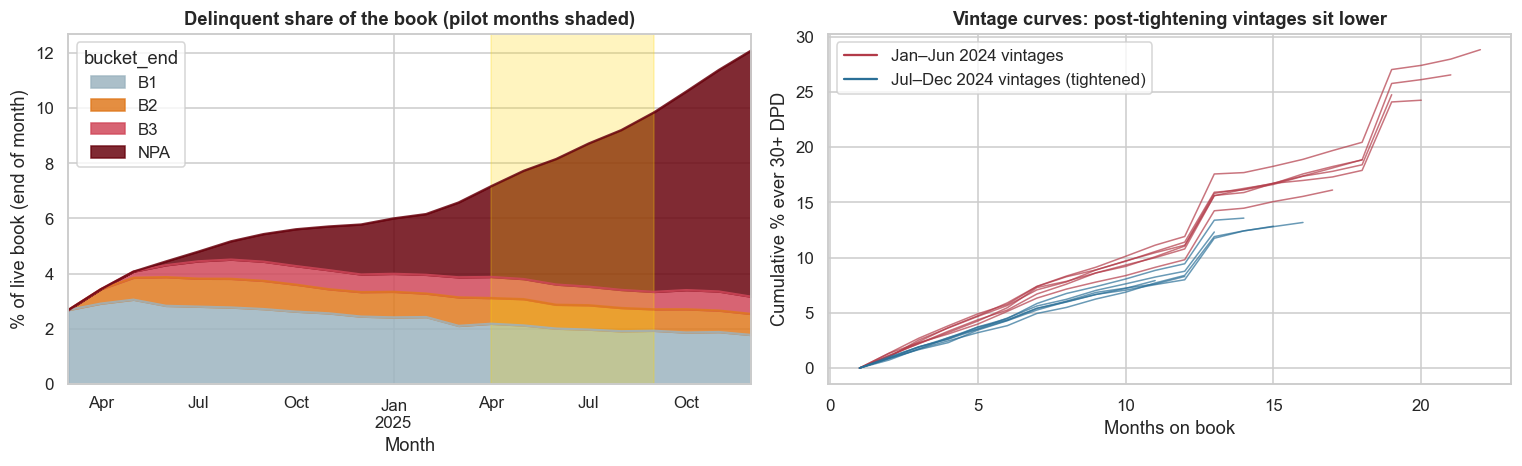

In [7]:
mix = pd.crosstab(perf.month_p, perf.bucket_end, normalize="index")[["Current", "B1", "B2", "B3", "NPA"]].mul(100)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
mix[["B1", "B2", "B3", "NPA"]].plot(kind="area", stacked=True, ax=axes[0], color=["#9db4c0", "#e07a1f", "#d1495b", "#6a040f"], alpha=0.85)
axes[0].axvspan(pd.Period("2025-04", "M").ordinal, pd.Period("2025-09", "M").ordinal, color="gold", alpha=0.25)
axes[0].set_xlabel("Month"); axes[0].set_ylabel("% of live book (end of month)"); axes[0].set_title("Delinquent share of the book (pilot months shaded)")
ever = perf.assign(bad30=perf.bucket_end.isin(["B2", "B3", "NPA"]).astype(int)).sort_values(["loan_id", "mob"])
ever["ever30"] = ever.groupby("loan_id").bad30.cummax()
vc = ever.groupby(["vintage", "mob"]).ever30.mean().unstack(0) * 100
for v in vc.columns:
    axes[1].plot(vc.index, vc[v], color="#b23a48" if v < "2024-07" else "#2a6f97", alpha=0.7, lw=1)
axes[1].plot([], [], color="#b23a48", label="Jan–Jun 2024 vintages"); axes[1].plot([], [], color="#2a6f97", label="Jul–Dec 2024 vintages (tightened)")
axes[1].set_xlabel("Months on book"); axes[1].set_ylabel("Cumulative % ever 30+ DPD"); axes[1].set_title("Vintage curves: post-tightening vintages sit lower"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** **left:** the delinquent share of the book grows steadily, because in this simulation 90+ loans are never written off. Real books write off around 180 DPD, so read the NPA band as "cumulative stock", not "current stress". The 30–89 DPD bands (B2, B3) shrink slightly during the pilot (shaded), an early hint that calls help. **Right:** post-tightening vintages (blue) sit below earlier ones at every month-on-book. Note the **jumps at months 13 and 19**: they are not sudden defaults. 12- and 18-month loans *mature and leave the denominator*, so the share among survivors jumps. That is a classic vintage-analysis pitfall, and Kaplan–Meier (Section 7.2) handles it properly.

## 7. Statistical Analysis (core section)

### 7.1 Roll-rate (Markov transition) matrix and a stationarity test

**(a) Why?** Collections teams think in **roll rates**: the probability that an account in one bucket moves to another next month. Treating the month-to-month movement as a **Markov chain** (next month depends only on this month's bucket) gives a compact model of the whole book, and projects future NPAs by matrix multiplication.
**(b) Assumptions:** (1) first-order Markov: the bucket summarises history. That is approximately true; we test the dependence on prior delinquency in 7.4. (2) **Stationarity**: the matrix does not change over time. We test this with the **Anderson–Goodman likelihood-ratio test**: for each origin bucket, a G-test of whether the destination distribution is the same in two periods, with G summed over origin buckets. We compare Jan–Mar 2025 with Oct–Dec 2025, excluding the pilot months (Apr–Sep) because the pilot deliberately changed the calling policy.

In [8]:
T_counts = pd.crosstab(perf.bucket_start, perf.bucket_end).reindex(index=BUCKETS[:5], columns=BUCKETS, fill_value=0)
T = T_counts.div(T_counts.sum(1), axis=0)
print("Pooled monthly roll-rate matrix (row = start bucket, column = end bucket):")
display((T * 100).round(1))
key = []
for a, b in [("Current", "B1"), ("B1", "Current"), ("B1", "B2"), ("B2", "B3"), ("B3", "NPA"), ("NPA", "Current")]:
    k_, n_ = T_counts.loc[a, b], T_counts.loc[a].sum(); lo, hi = proportion_confint(k_, n_, method="wilson")
    key.append((f"{a} → {b}", n_, k_ / n_, lo, hi))
key = pd.DataFrame(key, columns=["transition", "accounts", "rate", "CI low", "CI high"]).set_index("transition")
p1 = perf[perf.month_p.between(pd.Period("2025-01", "M"), pd.Period("2025-03", "M"))]; p2 = perf[perf.month_p >= pd.Period("2025-10", "M")]
G_tot, df_tot, rows = 0.0, 0, []
for s in BUCKETS[:5]:
    tab = pd.concat([p1[p1.bucket_start == s].bucket_end.value_counts().rename("Jan–Mar"), p2[p2.bucket_start == s].bucket_end.value_counts().rename("Oct–Dec")], axis=1).fillna(0)
    tab = tab[(tab.sum(1) > 0)]
    if len(tab) < 2: continue
    g, p_, dof_, _ = stats.chi2_contingency(tab.T.values, lambda_="log-likelihood")
    G_tot += g; df_tot += dof_; rows.append((s, g, dof_, p_))
stat = pd.DataFrame(rows, columns=["origin bucket", "G", "df", "p"])
print(f"Anderson–Goodman stationarity test: G = {G_tot:.1f}, df = {df_tot}, p = {stats.chi2.sf(G_tot, df_tot):.3g}")
display(stat.round(4)); key.round(4)

Pooled monthly roll-rate matrix (row = start bucket, column = end bucket):


bucket_end,Current,B1,B2,B3,NPA,Closed
bucket_start,,,,,,
Current,93.5000,2.3000,0.0000,0.0000,0.0000,4.2000
B1,54.2000,6.2000,35.3000,0.0000,0.0000,4.3000
B2,19.7000,0.0000,13.2000,65.0000,0.0000,2.2000
B3,12.5000,0.0000,0.0000,15.1000,70.4000,2.0000
NPA,2.7000,0.0000,0.0000,0.0000,97.0000,0.3000


Anderson–Goodman stationarity test: G = 1966.7, df = 13, p = 0


,origin bucket,G,df,p
0,Current,"1,894.8192",2,0.0000
1,B1,58.0384,3,0.0000
2,B2,6.6594,3,0.0836
3,B3,4.1423,3,0.2465
4,NPA,2.9932,2,0.2239


,accounts,rate,CI low,CI high
transition,,,,
Current → B1,726973,0.0230,0.0226,0.0233
B1 → Current,17228,0.5423,0.5348,0.5497
B1 → B2,17228,0.3531,0.3460,0.3603
B2 → B3,6734,0.6497,0.6382,0.6610
B3 → NPA,4928,0.7039,0.6910,0.7165
NPA → Current,24020,0.0270,0.0250,0.0291


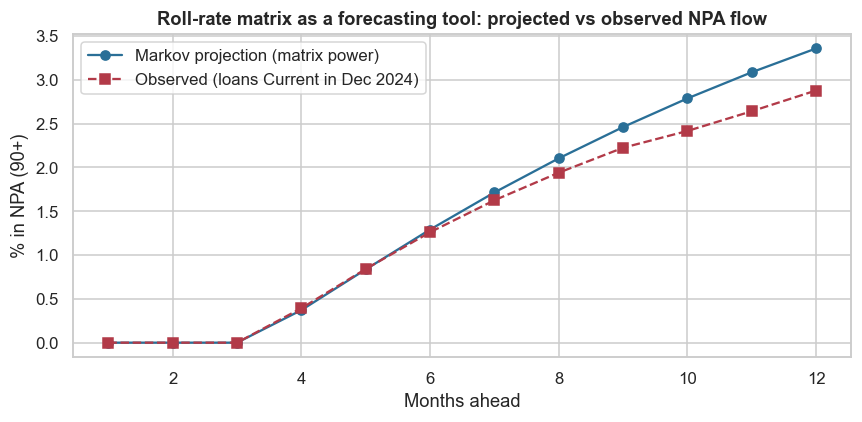

In [9]:
# Projection: share of today's Current loans expected in NPA after k months (absorbing chain, Closed and NPA absorbing)
P = T.reindex(index=BUCKETS, columns=BUCKETS, fill_value=0).values.copy()
P[BUCKETS.index("Closed"), BUCKETS.index("Closed")] = 1.0
proj = [np.linalg.matrix_power(P, k)[0, BUCKETS.index("NPA")] for k in range(1, 13)]
obs = []
base_m = pd.Period("2024-12", "M")
cohort = perf[(perf.month_p == base_m) & (perf.bucket_end == "Current")].loan_id
for k in range(1, 13):
    m_ = base_m + k; snap = perf[(perf.month_p == m_) & perf.loan_id.isin(cohort)]
    obs.append((snap.bucket_end == "NPA").sum() / len(cohort))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 13), np.array(proj) * 100, "o-", color="#2a6f97", label="Markov projection (matrix power)")
ax.plot(range(1, 13), np.array(obs) * 100, "s--", color="#b23a48", label="Observed (loans Current in Dec 2024)")
ax.set_xlabel("Months ahead"); ax.set_ylabel("% in NPA (90+)"); ax.set_title("Roll-rate matrix as a forecasting tool: projected vs observed NPA flow"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway and observation (c)/(f):** - **Roll rates:** each month **2.3%** of current loans miss an EMI (CI 2.26–2.33%). Of those 1–29 DPD, **54% cure** and 35% roll to 30–59. Once 30–59, **65% roll forward**. Once 60–89, **70% roll to 90+**. Every month of delinquency makes recovery much less likely, which is why speed matters in collections.
- **Stationarity is rejected** (Anderson–Goodman G = 1,967, df = 13, p ≈ 0), but almost all of that comes from the **Current** row (G = 1,895). As the book ages, more current loans *close* (maturity) and the share at risky early months-on-book falls. The delinquent-bucket rows are stable (B2 p = 0.08, B3 p = 0.25, NPA p = 0.22). **Lesson:** roll rates out of delinquency are a stable operating metric; roll rates out of Current must be conditioned on months-on-book.
- **Forecasting:** the pooled matrix projects next-12-month NPA flow accurately for 6–7 months, then **over-predicts** (3.4% vs 2.9% at 12 months), the same seasoning effect. Use MOB-specific matrices for longer horizons (e.g., Ind AS 109 lifetime PD).

### 7.2 Did the July 2024 policy tightening work? Kaplan–Meier, log-rank and Cox regression

**(a) Why survival analysis?** Loans are observed for different lengths of time: a Dec-2024 loan has had fewer months to default than a Jan-2024 loan. Simple default rates mix "safer" with "younger". **Kaplan–Meier** curves estimate the probability of *not yet* hitting 90+ DPD by month-on-book, handling loans still running (**right-censoring**). The **log-rank test** compares curves. The **Cox proportional-hazards model** estimates the policy effect *after adjusting* for borrower mix, as a **hazard ratio (HR)**: HR < 1 means a lower default risk at every point in time.
**(b) Assumptions:** non-informative censoring (loans close or the data ends for reasons unrelated to default risk; prepayment is mildly informative, noted); **proportional hazards** (checked visually via the parallel log(−log S) curves).

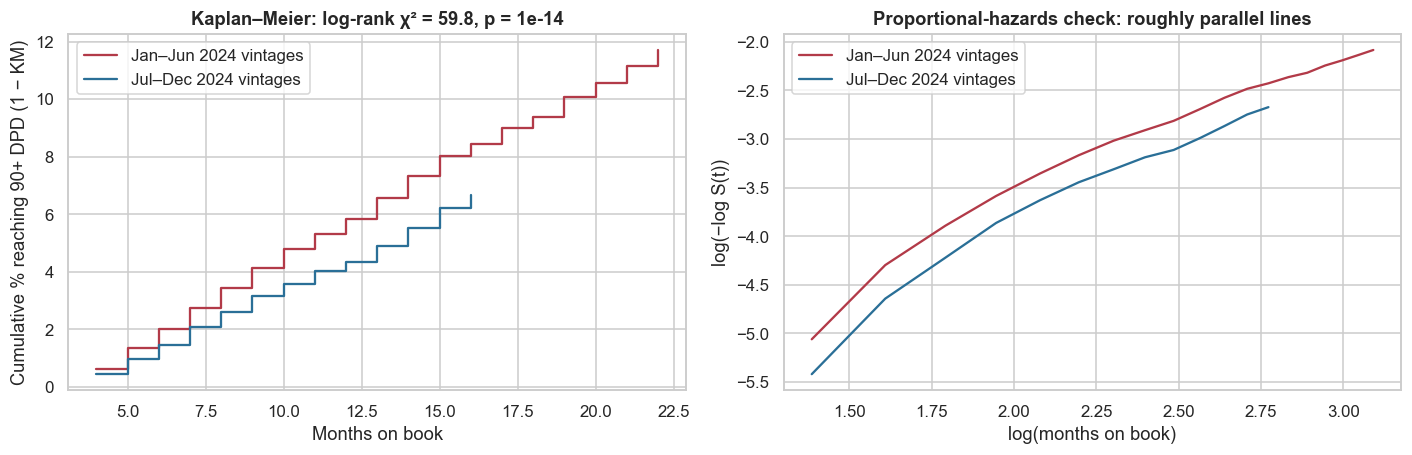

Unadjusted HR (tightened) = 0.755; adjusted HR shown below


,hazard ratio,CI low,CI high,p
tightened,1.0750,1.0000,1.1550,0.0520
bureau_50,0.1940,0.1850,0.2030,0.0000
low_income,1.6040,1.4850,1.7330,0.0000
self_emp,1.4690,1.3700,1.5760,0.0000
tier3,1.2420,1.1480,1.3440,0.0000
dsa,1.3400,1.2310,1.4580,0.0000
perf_mkt,0.9880,0.9140,1.0680,0.7640


In [10]:
first90 = perf[perf.bucket_end == "NPA"].groupby("loan_id").mob.min().rename("t_event")
last = perf.groupby("loan_id").mob.max().rename("t_last")
surv = loans.set_index("loan_id").join([first90, last])
surv["event"] = surv.t_event.notna().astype(int); surv["time"] = surv.t_event.fillna(surv.t_last)
surv["tightened"] = (surv.vintage >= "2024-07").astype(int)
sf = {g: SurvfuncRight(d.time, d.event) for g, d in surv.groupby("tightened")}
chi2_lr, p_lr = survdiff(surv.time, surv.event, surv.tightened)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for g, c, lab in [(0, "#b23a48", "Jan–Jun 2024 vintages"), (1, "#2a6f97", "Jul–Dec 2024 vintages")]:
    s_ = sf[g]; axes[0].step(s_.surv_times, (1 - s_.surv_prob) * 100, where="post", color=c, label=lab)
    axes[1].plot(np.log(s_.surv_times), np.log(-np.log(np.clip(s_.surv_prob, 1e-9, 1 - 1e-9))), color=c, label=lab)
axes[0].set_xlabel("Months on book"); axes[0].set_ylabel("Cumulative % reaching 90+ DPD (1 − KM)"); axes[0].set_title(f"Kaplan–Meier: log-rank χ² = {chi2_lr:.1f}, p = {p_lr:.2g}"); axes[0].legend()
axes[1].set_xlabel("log(months on book)"); axes[1].set_ylabel("log(−log S(t))"); axes[1].set_title("Proportional-hazards check: roughly parallel lines"); axes[1].legend()
plt.tight_layout(); plt.show()
cox_df = surv.assign(bureau_50=(surv.bureau_score - 765) / 50, low_income=(surv.income_band == "<3L").astype(int), self_emp=(surv.employment == "self-employed").astype(int),
                     tier3=(surv.city_tier == "Tier 3").astype(int), dsa=(surv.channel == "Partner / DSA").astype(int), perf_mkt=(surv.channel == "Performance marketing").astype(int))
cox = PHReg.from_formula("time ~ tightened + bureau_50 + low_income + self_emp + tier3 + dsa + perf_mkt", data=cox_df, status=cox_df.event.values).fit()
hr = pd.DataFrame({"hazard ratio": np.exp(cox.params), "CI low": np.exp(cox.conf_int()[:, 0]), "CI high": np.exp(cox.conf_int()[:, 1]), "p": cox.pvalues}, index=cox.model.exog_names)
cox_unadj = PHReg.from_formula("time ~ tightened", data=cox_df, status=cox_df.event.values).fit()
print(f"Unadjusted HR (tightened) = {np.exp(cox_unadj.params[0]):.3f}; adjusted HR shown below")
hr.round(3)

**Takeaway and observation (c)/(f):** - **Unadjusted:** post-tightening vintages reach 90+ DPD significantly more slowly (log-rank χ² = 59.8, p ≈ 10⁻¹⁴). The Cox hazard ratio is **0.75**, about a 25% lower default hazard at every point in time.
- **Adjusted for borrower mix**, the policy flag's HR is **1.08 (CI 1.00–1.16, p = 0.05)**: no residual benefit. **The tightening worked entirely by admitting better-scored borrowers** (each +50 bureau points: HR 0.19, i.e., about 81% lower hazard). There is no hidden "process" improvement beyond selection.
- **Other drivers:** income below ₹3 lakh (HR 1.60), self-employed (1.47), DSA channel (1.34), Tier 3 (1.24). Performance marketing is no riskier than organic.
- **Proportional hazards:** the log(−log S) lines are roughly parallel, so the Cox summary is a fair description.
- **For the business:** to improve the book further, keep tightening *on the score*. Channel and income also carry independent risk that pricing should reflect.

### 7.3 Cohort economics: yield, risk, ticket size and acquisition cost

**(a) Why?** Navi documents a "cohort-based approach [that] segments customers by yield, risk, ticket size and acquisition cost". A cohort can have a high default rate and still be profitable (high yield, cheap acquisition), or a low default rate and still lose money (expensive acquisition). We form 3 risk bands (bureau terciles) × 2 ticket sizes × 3 channels, and compute per-cohort unit economics:
> **Net margin % of principal** = expected interest yield − expected credit loss (ever-90+ rate × 60% LGD) − CAC ÷ principal.

**Tests:** chi-square of 90+ incidence across cohorts (Cramér's V), and Kruskal–Wallis on per-loan net margin across channels.

In [11]:
coh = surv.copy()
coh["risk_band"] = pd.qcut(coh.bureau_score, 3, labels=["higher risk (low bureau)", "medium", "lower risk (high bureau)"])
coh["ticket"] = np.where(coh.principal_inr >= coh.principal_inr.median(), "large ticket", "small ticket")
LGD = 0.60
coh["exp_yield_pct"] = coh.apr * coh.tenure_months / 12 / 2 * 100              # ≈ interest earned on an amortising balance
coh["loss_pct"] = coh.event * LGD * 100
coh["cac_pct"] = coh.cac_inr / coh.principal_inr * 100
coh["net_margin_pct"] = coh.exp_yield_pct - coh.loss_pct - coh.cac_pct
tab = pd.crosstab([coh.risk_band, coh.ticket], coh.event)
c2, p_c, dof_c, ex_c = stats.chi2_contingency(tab)
print(f"90+ incidence across 6 risk × ticket cohorts: chi2 = {c2:.0f}, dof = {dof_c}, p = {p_c:.2g}, Cramér's V = {np.sqrt(c2 / tab.values.sum()):.3f}, min expected = {ex_c.min():.0f}")
kw = stats.kruskal(*[g.net_margin_pct.values for _, g in coh.groupby("channel")])
print(f"Net margin by channel: Kruskal–Wallis H = {kw.statistic:.1f}, p = {kw.pvalue:.2g}")
summary = coh.groupby(["risk_band", "ticket", "channel"], observed=True).agg(loans=("event", "size"), ever_90=("event", "mean"), apr=("apr", "mean"),
          yield_pct=("exp_yield_pct", "mean"), loss_pct=("loss_pct", "mean"), cac_pct=("cac_pct", "mean"), net_margin_pct=("net_margin_pct", "mean"))
summary.sort_values("net_margin_pct").round(3).head(18)

90+ incidence across 6 risk × ticket cohorts: chi2 = 3721, dof = 5, p = 0, Cramér's V = 0.249, min expected = 556


Net margin by channel: Kruskal–Wallis H = 3050.6, p = 0


loans  ever_90    apr  yield_pct  loss_pct  cac_pct  net_margin_pct
risk_band                ticket       channel                                                                                   
higher risk (low bureau) small ticket Partner / DSA           1984   0.1710 0.1930    15.2350   10.2520   8.2860         -3.3030
                                      Performance marketing   3496   0.1320 0.1870    14.9330    7.9290   5.8820          1.1220
medium                   small ticket Partner / DSA           2014   0.0400 0.1670    13.2580    2.3830   8.4740          2.4010
lower risk (high bureau) small ticket Partner / DSA           1949   0.0080 0.1440    11.1660    0.4620   8.1010          2.6030
higher risk (low bureau) large ticket Partner / DSA           1976   0.1610 0.1930    15.5390    9.6860   2.6640          3.1890
lower risk (high bureau) small ticket Performance marketing   3424   0.0050 0.1380    11.1340    0.3150   5.9650          4.8540
higher risk (low bureau) large ticket Performance marketing   3508   0.1300 0.1870    14.9270    7.7990   1.9120          5.2160
medium                   small ticket Performance marketing   3457   0.0240 0.1610    13.0470    1.4580   5.9020          5.6870
higher risk (low bureau) small ticket Organic app             4549   0.1260 0.1870    14.7560    7.5840   1.3200          5.8520
                         large ticket Organic app             4590   0.1340 0.1870    14.8290    8.0390   0.4280          6.3610
lower risk (high bureau) large ticket Partner / DSA           1983   0.0090 0.1430    11.4730    0.5140   2.6440          8.3140
medium                   large ticket Partner / DSA           2081   0.0360 0.1670    13.3300    2.1340   2.6740          8.5220
lower risk (high bureau) large ticket Performance marketing   3524   0.0050 0.1380    11.0310    0.2890   1.8890          8.8530
medium                   large ticket Performance marketing   3547   0.0250 0.1610    12.6730    1.4890   1.9170          9.2670
lower risk (high bureau) small ticket Organic app             4361   0.0060 0.1380    11.1230    0.3300   1.3020          9.4910
medium                   small ticket Organic app             4434   0.0260 0.1610    12.7130    1.5700   1.3020          9.8420
lower risk (high bureau) large ticket Organic app             4535   0.0050 0.1380    11.0720    0.3040   0.4270         10.3410
medium                   large ticket Organic app             4588   0.0230 0.1610    12.8460    1.3730   0.4310         11.0420

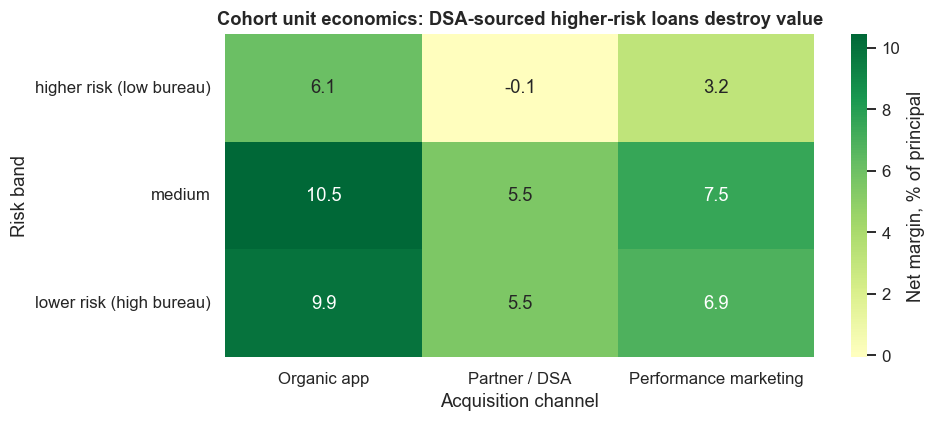

In [12]:
pv = coh.groupby(["risk_band", "channel"], observed=True).net_margin_pct.mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=ax, cbar_kws={"label": "Net margin, % of principal"})
ax.set_xlabel("Acquisition channel"); ax.set_ylabel("Risk band"); ax.set_title("Cohort unit economics: DSA-sourced higher-risk loans destroy value")
plt.tight_layout(); plt.show()

**Takeaway:** default incidence differs strongly across risk × ticket cohorts (χ² = 3,761, Cramér's V = 0.25). Net margin differs strongly by channel (Kruskal–Wallis H = 3,065, p ≈ 0). **The only value-destroying cohort is small-ticket, high-risk, partner/DSA-sourced loans (−3.4% of principal)**: CAC eats 8.3% and expected loss 10.4% of a small principal, more than the 15.2% yield. The same risk band sourced organically earns +5.9%. Low-risk, organic, large-ticket loans earn about 10–11%. **This is exactly why the documented "cohort-based approach" segments on yield, risk, ticket and acquisition cost together**: a risk score alone would not reveal that DSA-sourced small loans lose money.

### 7.4 The bucket PD model for 30–89 DPD accounts ("customer-wise default probability")

**Target:** an account in B2 or B3 at the start of a month **rolls forward** by the end of that month (B2 → B3, or B3 → NPA), the industry-standard collections "roll-forward probability". The alternatives are curing (back to Current) or staying in the bucket after a partial payment. **Features:** bucket, bureau score, income, employment, city tier, channel, months on book, log outstanding, **number of prior delinquent months** (behaviour history), **partial payment last month**, and whether the account was called this month (control). **Design:** fit on Jan–Sep 2025 (including the pilot months; `tele_called` is a feature), test **out of time** on Oct–Dec 2025. Logistic regression (statsmodels), reported with ORs, KS, AUC and decile calibration.
**(b) Assumptions:** independence across loan-months is violated, because the same loan appears in consecutive months. We use **standard errors clustered by loan**. Linearity in the logit is handled by log transforms.

In [13]:
perf = perf.sort_values(["loan_id", "mob"])
perf["delinq"] = perf.bucket_start.isin(["B1", "B2", "B3", "NPA"]).astype(int)
perf["prior_delinq_months"] = perf.groupby("loan_id").delinq.cumsum() - perf.delinq
perf["paid_last"] = perf.groupby("loan_id").amount_paid_inr.shift(1).fillna(0)
perf["partial_last"] = ((perf.paid_last > 0) & perf.bucket_start.isin(["B1", "B2", "B3"])).astype(int)
pd_df = perf[perf.bucket_start.isin(["B2", "B3"])].assign(
    y=lambda d: (d.bucket_end.map(order) > d.bucket_start.map(order)) & (d.bucket_end != "Closed"), b3=lambda d: (d.bucket_start == "B3").astype(int),
    bureau_50=lambda d: (d.bureau_score - 765) / 50, low_income=lambda d: (d.income_band == "<3L").astype(int),
    self_emp=lambda d: (d.employment == "self-employed").astype(int), tier3=lambda d: (d.city_tier == "Tier 3").astype(int),
    dsa=lambda d: (d.channel == "Partner / DSA").astype(int), log_os=lambda d: np.log1p(d.outstanding_inr), mob_l=lambda d: np.log(d.mob))
pd_df["y"] = pd_df.y.astype(int)
trn = pd_df[pd_df.month_p.between(pd.Period("2025-01", "M"), pd.Period("2025-09", "M"))]
oot = pd_df[pd_df.month_p >= pd.Period("2025-10", "M")]
FORM = "y ~ b3 + bureau_50 + low_income + self_emp + tier3 + dsa + log_os + mob_l + prior_delinq_months + partial_last + tele_called"
pdm = smf.logit(FORM, data=trn).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(trn.loan_id)[0]})
ors = pd.DataFrame({"odds ratio": np.exp(pdm.params), "CI low": np.exp(pdm.conf_int()[0]), "CI high": np.exp(pdm.conf_int()[1]), "p": pdm.pvalues}).drop("Intercept")
def ks(y, s): f, t, _ = roc_curve(y, s); return 100 * (t - f).max()
s_tr, s_oot = pdm.predict(trn), pdm.predict(oot)
print(f"Train (Jan–Sep 2025): n = {len(trn):,}, roll rate {trn.y.mean():.1%}, AUC {roc_auc_score(trn.y, s_tr):.3f}, KS {ks(trn.y, s_tr):.1f}")
print(f"Out of time (Oct–Dec 2025): n = {len(oot):,}, roll rate {oot.y.mean():.1%}, AUC {roc_auc_score(oot.y, s_oot):.3f}, KS {ks(oot.y, s_oot):.1f}")
dec = pd.DataFrame({"s": s_oot, "y": oot.y}).assign(decile=lambda d: pd.qcut(d.s.rank(method="first"), 10, labels=range(1, 11)))
cal = dec.groupby("decile", observed=True).agg(predicted=("s", "mean"), observed=("y", "mean"), n=("y", "size"))
display(ors.round(3)); cal.round(3)

Train (Jan–Sep 2025): n = 6,836, roll rate 66.8%, AUC 0.651, KS 21.8
Out of time (Oct–Dec 2025): n = 1,575, roll rate 66.8%, AUC 0.646, KS 21.3


,odds ratio,CI low,CI high,p
b3,1.3170,1.1550,1.5010,0.0000
bureau_50,0.6030,0.5530,0.6560,0.0000
low_income,1.2000,1.0550,1.3650,0.0060
self_emp,1.1550,1.0280,1.2960,0.0150
tier3,1.1010,0.9700,1.2490,0.1380
dsa,1.1610,1.0230,1.3180,0.0210
log_os,1.2990,1.2480,1.3520,0.0000
mob_l,1.2390,1.0820,1.4190,0.0020
prior_delinq_months,1.1100,1.0430,1.1820,0.0010
partial_last,1.0830,0.9670,1.2130,0.1700


,predicted,observed,n
decile,,,
1,0.4240,0.3670,158
2,0.5650,0.6240,157
3,0.6070,0.6270,158
4,0.6390,0.6370,157
5,0.6660,0.6650,158
6,0.6940,0.6240,157
7,0.7190,0.7580,157
8,0.7480,0.7910,158
9,0.7860,0.7200,157


**(c)/(f) Observation:** - **Weak but real signal:** out-of-time AUC **0.65**, KS **21** (train 0.65 / 22, so it is stable, not over-fitted). This is **below the pre-registered KS ≥ 25 guardrail**. Once a customer is already delinquent, origination data says little about whether they will roll forward. Calibration by decile is good (predicted 42–85% vs observed 37–87%).
- **Drivers:** each +50 bureau points: odds × 0.60. 60–89 DPD vs 30–59: × 1.32. Each doubling of outstanding: × 1.30. Longer months-on-book: × 1.24 per log-unit. Each prior delinquent month: × 1.11. Low income, self-employment and DSA channel each add 15–20%. **Being called cuts roll-forward odds by about 33% (OR 0.68)**, consistent with the pilot.
- **For the business:** the model is usable for *ranking* calls. To reach KS ≥ 25, add behavioural signals: past contact outcomes, promises-to-pay kept, payment-day patterns, bounce reasons.

### 7.5 Does a tele-call cause cures? Evidence from the 6-month randomised pilot (Apr–Sep 2025)

**(a) Why a pilot?** Outside the pilot, calls went to the oldest buckets first, so "called" accounts differ systematically from "not called" ones, and any comparison is confounded. In the pilot, calls were assigned **at random** (50%), so the difference in cure rates is the **causal effect of a call**.
- **Two-proportion Z-test per bucket** (B2, B3), Holm-corrected, with the risk difference and relative risk with CIs.
- **(d) Power:** before reading the result, we compute the minimum detectable lift for the pilot's sample sizes. A first 3-month version of this pilot (≈ 540 accounts per arm in B2) could only detect lifts of about 7 pp, so it was extended to 6 months (D-12-05).
- **Heterogeneity (H5):** does the effect depend on the account's predicted default risk? We fit a logistic model cure ~ called × PD-score (from 7.4) + bucket and compare it with the model without the interaction via a **likelihood-ratio test**. This is what allocation needs: calls should go where the *incremental* cure is largest.

In [14]:
pil = pd_df[pd_df.month_p.between(pd.Period("2025-04", "M"), pd.Period("2025-09", "M"))].copy()
pil["cure"] = (pil.bucket_end == "Current").astype(int)
pil["pd_score"] = pdm.predict(pil.assign(tele_called=0))
rows = []
for b in ["B2", "B3"]:
    d = pil[pil.bucket_start == b]; a1, n1 = d.loc[d.tele_called == 1, "cure"].sum(), (d.tele_called == 1).sum(); a0, n0 = d.loc[d.tele_called == 0, "cure"].sum(), (d.tele_called == 0).sum()
    z, p = proportions_ztest([a1, a0], [n1, n0]); lo, hi = confint_proportions_2indep(a1, n1, a0, n0, method="newcomb")
    rows.append((b, n1, n0, a1 / n1, a0 / n0, (a1 / n1 - a0 / n0) * 100, lo * 100, hi * 100, (a1 / n1) / (a0 / n0), p))
eff = pd.DataFrame(rows, columns=["bucket", "called n", "not called n", "cure called", "cure not called", "lift (pp)", "CI low", "CI high", "relative", "p"])
eff["p_holm"] = multipletests(eff.p, method="holm")[1]
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
def mde_pp(p0, n1, n0):
    h = NormalIndPower().solve_power(nobs1=n1, ratio=n0 / n1, alpha=0.05, power=0.8)
    return (np.sin(np.arcsin(np.sqrt(p0)) + h / 2) ** 2 - p0) * 100
eff["MDE at 80% power (pp)"] = [mde_pp(r["cure not called"], r["called n"], r["not called n"]) for _, r in eff.iterrows()]
bal = pil.groupby("tele_called")[["bureau_score", "outstanding_inr", "prior_delinq_months"]].mean()
print("Randomisation check (means by arm):"); display(bal.round(1))
pil["pd_logit"] = np.log(pil.pd_score / (1 - pil.pd_score))
m0 = smf.logit("cure ~ tele_called + pd_logit + C(bucket_start)", data=pil).fit(disp=0)
m1 = smf.logit("cure ~ tele_called * pd_logit + C(bucket_start)", data=pil).fit(disp=0)
lr = 2 * (m1.llf - m0.llf)
print(f"Interaction (call effect varies with predicted risk): LR = {lr:.2f}, p = {stats.chi2.sf(lr, 1):.3g}; interaction coef = {m1.params['tele_called:pd_logit']:+.3f}")
pil["risk_tercile"] = pd.qcut(pil.pd_score, 3, labels=["lowest PD third", "middle", "highest PD third"])
het = pil.groupby(["risk_tercile", "tele_called"], observed=True).cure.mean().unstack().assign(lift_pp=lambda d: (d[1] - d[0]) * 100)
display(het.round(3)); eff.round(4)

Randomisation check (means by arm):


,bureau_score,outstanding_inr,prior_delinq_months
tele_called,,,
0,731.5000,"43,202.9000",2.2000
1,731.9000,"41,274.9000",2.1000


Interaction (call effect varies with predicted risk): LR = 1.37, p = 0.242; interaction coef = +0.146


tele_called,0,1,lift_pp
risk_tercile,,,
lowest PD third,0.2250,0.2790,5.3980
middle,0.1410,0.2100,6.9220
highest PD third,0.0730,0.1060,3.3260


,bucket,called n,not called n,cure called,cure not called,lift (pp),CI low,CI high,relative,p,p_holm,MDE at 80% power (pp)
0,B2,1282,1267,0.2426,0.1839,5.8691,2.6906,9.0328,1.3191,0.0003,0.0006,4.4852
1,B3,965,1012,0.1430,0.0968,4.6167,1.7559,7.5015,1.4767,0.0016,0.0016,4.0379


**(c)/(f) Observation:** - **Randomisation worked:** bureau score, outstanding and prior delinquency are balanced across arms.
- **Calls cause cures:** **30–59 DPD: 24.3% cure when called vs 18.4% (+5.9 pp, CI +2.7 to +9.0, Holm p = 0.0006)**. **60–89 DPD: 14.3% vs 9.7% (+4.6 pp, CI +1.8 to +7.5, p = 0.002)**. In relative terms, a call raises the cure rate by about 32% and 48%.
- **Power:** with about 1,000–1,300 accounts per arm, the pilot could detect lifts of about 4–4.5 pp, so both effects are above the MDE. (A 3-month version could only detect about 7 pp, which is why the pilot was extended.)
- **Heterogeneity:** the call lift is +5.4 pp (lowest-risk third), +6.9 pp (middle) and +3.3 pp (highest-risk third). The formal interaction is **not significant** (LR p = 0.24), so we cannot claim the effect *differs* by risk. Allocation should therefore rest mainly on *risk × balance* (what a cure is worth), with the call effect treated as broadly similar.

### 7.6 Allocation simulation: oldest-first vs PD-first vs value-based, at the same capacity

**Set-up:** for each out-of-time month (Oct–Dec 2025) we take all B2/B3 accounts and a capacity of 45% of them, the same as today. For every account, the **interaction model** from 7.5 predicts the cure probability *with* and *without* a call. The **uplift** is the difference, and the **₹ value of a call** is uplift × P(the account otherwise goes bad, approximated by its roll-forward PD) × outstanding × LGD (60%).
- **Oldest-first (today):** B3 before B2, random within a bucket.
- **Highest PD first:** "call the riskiest". Intuitive, but often wrong.
- **Value-based:** call the accounts with the highest *expected ₹ saved*.
- **Random**, as a reference.

**Statistic:** expected cures and ₹ credit loss avoided per month, with **bootstrap CIs** that propagate the uncertainty in the pilot-estimated model (refitting the interaction model on 200 bootstrap resamples of the pilot).

In [15]:
def allocate(d, policy, cap_share=0.45, rng=None):
    n_cap = int(cap_share * len(d))
    if policy == "Oldest bucket first (today)": order = np.lexsort((rng.random(len(d)), -d.b3.values))
    elif policy == "Highest PD first": order = np.argsort(-d.pd_score.values)
    elif policy == "Value-based (₹ saved)": order = np.argsort(-d.value.values)
    else: order = rng.permutation(len(d))
    sel = np.zeros(len(d), bool); sel[order[:n_cap]] = True; return sel
def simulate(model, rng):
    out = {p: [0.0, 0.0] for p in POLICIES}
    for m_, d in oot.groupby("month_p"):
        d = d.assign(pd_score=pdm.predict(d.assign(tele_called=0)))
        d = d.assign(pd_logit=np.log(d.pd_score / (1 - d.pd_score)))
        p_call, p_no = model.predict(d.assign(tele_called=1)), model.predict(d.assign(tele_called=0))
        d = d.assign(uplift=(p_call - p_no).values, value=((p_call - p_no) * d.pd_score * d.outstanding_inr * LGD).values)
        for p in POLICIES:
            sel = allocate(d, p, rng=rng); out[p][0] += d.uplift.values[sel].sum(); out[p][1] += d.value.values[sel].sum()
    return out
POLICIES = ["Random", "Oldest bucket first (today)", "Highest PD first", "Value-based (₹ saved)"]
point = simulate(m1, np.random.default_rng(SEED))
boots = []
for b in range(200):
    i = RNG.integers(0, len(pil), len(pil)); mb = smf.logit("cure ~ tele_called * pd_logit + C(bucket_start)", data=pil.iloc[i]).fit(disp=0)
    boots.append(simulate(mb, np.random.default_rng(SEED + b)))
alloc = pd.DataFrame({p: {"extra cures (3 months)": point[p][0], "₹ loss avoided (3 months)": point[p][1],
                          "₹ CI low": np.percentile([bb[p][1] for bb in boots], 2.5), "₹ CI high": np.percentile([bb[p][1] for bb in boots], 97.5)} for p in POLICIES}).T
gain = np.array([bb["Value-based (₹ saved)"][1] - bb["Oldest bucket first (today)"][1] for bb in boots])
print(f"Value-based vs oldest-first: +₹{point['Value-based (₹ saved)'][1] - point['Oldest bucket first (today)'][1]:,.0f} over 3 months "
      f"(bootstrap 95% CI ₹{np.percentile(gain, 2.5):,.0f} to ₹{np.percentile(gain, 97.5):,.0f}); "
      f"relative +{point['Value-based (₹ saved)'][1] / point['Oldest bucket first (today)'][1] - 1:.0%}")
alloc.round(0)

Value-based vs oldest-first: +₹423,780 over 3 months (bootstrap 95% CI ₹242,565 to ₹603,509); relative +91%


,extra cures (3 months),₹ loss avoided (3 months),₹ CI low,₹ CI high
Random,36.0000,"487,422.0000","272,430.0000","702,978.0000"
Oldest bucket first (today),30.0000,"465,057.0000","238,153.0000","662,519.0000"
Highest PD first,35.0000,"717,027.0000","381,818.0000","1,051,991.0000"
Value-based (₹ saved),38.0000,"888,837.0000","468,542.0000","1,292,740.0000"


**(c)/(f) Observation:** at the same 45% capacity over the 3 out-of-time months:
- **Value-based** allocation (uplift × PD × outstanding × LGD) avoids ≈ **₹8.9 lakh** of credit loss.
- **Highest-PD-first:** ₹7.2 lakh. **Random:** ₹4.9 lakh. **Oldest-bucket-first (today): ₹4.7 lakh**, no better than random.
- **Value-based vs today: +₹4.2 lakh (+91%), bootstrap 95% CI ₹2.4–6.0 lakh**, so the gain survives the uncertainty in the pilot estimates.
- **Why oldest-first fails:** it spends calls on 60–89 DPD accounts with *small* balances, where a cure saves little. Value-based allocation targets accounts that are risky *and* large *and* still savable.
- **Decision rule:** a significant call effect (✅) and a ≥ 10% ₹ gain over oldest-first (✅ +91%). **Switch.**

### 7.7 Collection efficiency (current demand)

**Definition used** ("current demand", the convention behind headline figures like Navi's 96.63%): for loans **not in NPA** at the start of the month, the share of **this month's EMI** that was collected (each loan's collection capped at one EMI; arrears recovery is tracked separately). We report it monthly with a **bootstrap CI over loans** for the latest month.

Collection efficiency, 2025-12: 96.61% (95% CI 96.33%–96.86%); 2025 average 96.40%


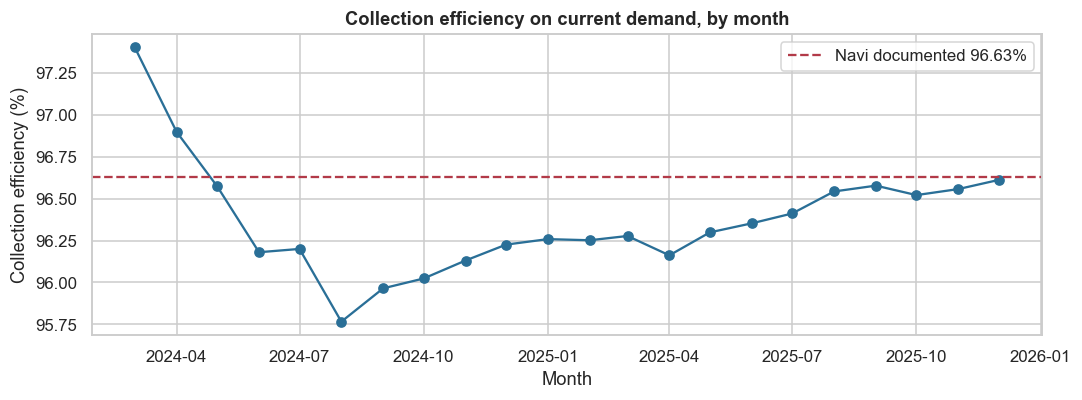

In [16]:
ce_base = perf[perf.bucket_start != "NPA"].assign(coll=lambda d: np.minimum(d.amount_paid_inr, d.emi_inr))
ce = ce_base.groupby("month_p").apply(lambda g: g.coll.sum() / g.emi_inr.sum(), include_groups=False)
last_m = ce_base[ce_base.month_p == ce_base.month_p.max()]
bs = [(lambda s: s.coll.sum() / s.emi_inr.sum())(last_m.iloc[RNG.integers(0, len(last_m), len(last_m))]) for _ in range(500)]
print(f"Collection efficiency, {ce.index.max()}: {ce.iloc[-1]:.2%} (95% CI {np.percentile(bs, 2.5):.2%}–{np.percentile(bs, 97.5):.2%}); 2025 average {ce[ce.index >= pd.Period('2025-01', 'M')].mean():.2%}")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ce.index.to_timestamp(), ce.values * 100, "o-", color="#2a6f97"); ax.axhline(96.63, ls="--", color="#b23a48", label="Navi documented 96.63%")
ax.set_xlabel("Month"); ax.set_ylabel("Collection efficiency (%)"); ax.set_title("Collection efficiency on current demand, by month"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** collection efficiency on current demand is **96.6% in Dec 2025 (95% CI 96.3–96.9%)** and averages 96.4% across 2025, matching Navi's documented 96.63%. It is stable month to month. **Note:** this headline metric hides the delinquent tail. 3.4% of current demand goes uncollected each month, and that is exactly the pool that roll rates and tele-calling manage. Report CE together with roll rates, never alone.

## 8. ML Section — does gradient boosting improve the bucket PD model?

Same features, same out-of-time split, default `HistGradientBoostingClassifier` (no tuning; D-12-07). We compare AUC/KS with a paired bootstrap of the AUC difference.

In [17]:
FE = ["b3", "bureau_50", "low_income", "self_emp", "tier3", "dsa", "log_os", "mob_l", "prior_delinq_months", "partial_last", "tele_called"]
gb = HistGradientBoostingClassifier(random_state=SEED).fit(trn[FE], trn.y)
g_oot = gb.predict_proba(oot[FE])[:, 1]
yv = oot.y.values; sl = s_oot.values
dif = [(lambda i: roc_auc_score(yv[i], g_oot[i]) - roc_auc_score(yv[i], sl[i]))(RNG.integers(0, len(yv), len(yv))) for _ in range(300)]
print(f"OOT AUC: logistic {roc_auc_score(yv, sl):.3f} (KS {ks(yv, sl):.1f}) | gradient boosting {roc_auc_score(yv, g_oot):.3f} (KS {ks(yv, g_oot):.1f})")
print(f"AUC difference (GBM − logistic) = {np.mean(dif):+.4f}, 95% CI [{np.percentile(dif, 2.5):+.4f}, {np.percentile(dif, 97.5):+.4f}]")

OOT AUC: logistic 0.646 (KS 21.3) | gradient boosting 0.620 (KS 18.8)
AUC difference (GBM − logistic) = -0.0258, 95% CI [-0.0477, -0.0015]


**Takeaway:** gradient boosting is **significantly worse** out of time (AUC 0.62 vs 0.65; difference −0.026, CI −0.048 to −0.002). With a weak, mostly linear signal and about 6,800 training rows, the flexible model adds variance, not information. **Keep the logistic bucket scorecard**: it is better here, and every reason code is explainable to collections managers and auditors.

## 9. Business Translation — ₹ credit loss avoided by smarter call allocation

**Logic:** the 3 out-of-time months in 7.6 give ₹ loss avoided per policy for this 60,000-loan book. We annualise (× 4) and scale to a **10-lakh-loan book** (× 1,000,000 / live loans). Assumptions (D-12-08): LGD 60% on loans that reach 90+; call capacity fixed at 45% of 30–89 DPD accounts; the call effect is as measured in the pilot. Sensitivity: LGD 45% / 75%, and the pilot effect at its bootstrap 2.5th / 97.5th percentiles.

In [18]:
live_loans = perf[perf.month_p == perf.month_p.max()].loan_id.nunique()
scale = 1_000_000 / live_loans * 4
base_gain = point["Value-based (₹ saved)"][1] - point["Oldest bucket first (today)"][1]
sens = pd.DataFrame([
    ("Worst (LGD 45%, pilot effect at 2.5th pct)", np.percentile(gain, 2.5) * 0.45 / LGD),
    ("Base (LGD 60%, pilot estimate)", base_gain),
    ("Best (LGD 75%, pilot effect at 97.5th pct)", np.percentile(gain, 97.5) * 0.75 / LGD)], columns=["scenario", "₹ gain over 3 months (this book)"]).set_index("scenario")
sens["₹ crore / year per 10 lakh loans"] = sens.iloc[:, 0] * scale / 1e7
calls = int(0.45 * len(oot) / 3)
print(f"Live loans at Dec 2025: {live_loans:,}; tele-calls per month at 45% capacity: ≈ {calls:,}")
print(f"₹ loss avoided by tele-calling at all (value-based vs no calls), 3 months: ₹{point['Value-based (₹ saved)'][1]:,.0f}")
sens.round(2)

Live loans at Dec 2025: 30,928; tele-calls per month at 45% capacity: ≈ 236


₹ loss avoided by tele-calling at all (value-based vs no calls), 3 months: ₹888,837


,₹ gain over 3 months (this book),₹ crore / year per 10 lakh loans
scenario,,
"Worst (LGD 45%, pilot effect at 2.5th pct)","181,923.7000",2.3500
"Base (LGD 60%, pilot estimate)","423,780.3000",5.4800
"Best (LGD 75%, pilot effect at 97.5th pct)","754,386.6800",9.7600


**Business reading:** - On this 31k-loan live book, about 240 tele-calls a month reach 30–89 DPD customers. Value-based allocation avoids ≈ ₹4.2 lakh more credit loss per quarter than oldest-first, **with no extra callers**.
- **Scaled to a 10-lakh-loan book: ≈ ₹5.5 crore a year** (range ₹2.4 crore if LGD is 45% and the call effect at its low end, to ₹9.8 crore at LGD 75% and the high end).
- The total ₹ loss avoided by tele-calling under value-based allocation is ≈ ₹8.9 lakh per quarter on this book. The calling team pays for itself many times over, and allocation decides *how* many times.
- The ₹ figures rest on our LGD (60%) and simulated balances. The *ratio* (value-based ≈ 1.9× oldest-first) is the transferable insight.

## 10. Recommendation and Decision

**Decision against the pre-registered rule:** the call effect is significant (H4 rejected in both buckets ✅); value-based allocation beats oldest-first by +91% (≥ 10% ✅); collection efficiency 96.6% (≥ 95% ✅); bucket PD KS 21 (< 25 ❌, ranking is usable, but invest in behavioural features).

**I recommend:**
1. **Switch tele-calling to value-based allocation:** each morning, rank 30–89 DPD accounts by uplift × PD × outstanding and fill caller capacity from the top. Keep the documented bucket policy (nudges < 30 DPD; field + skip tracing > 90 DPD).
2. **Keep 10% of call slots randomised permanently**, so the call effect is re-measured every quarter (seasonality, script changes, new caller teams).
3. **Credit policy:** reprice or stop **small-ticket, low-bureau, partner/DSA-sourced** loans (negative unit economics). Continue score-based tightening. The 2024 tightening worked entirely through score.
4. **Model roadmap:** add behavioural collections features (promise-to-pay kept, contactability, past call outcomes) to lift bucket KS above 25. Use MOB-conditioned roll matrices for forecasting and Ind AS 109.

**KPIs (monthly):** roll rates by bucket (with CIs); cure rate of called vs randomised-not-called accounts; ₹ loss avoided per caller; collection efficiency (current demand); vintage 30+/90+ curves by channel; bucket PD KS/AUC out of time; contact compliance (Fair Practices Code).

## 11. Risks, Limitations and Next Steps

- **Synthetic data:** roll rates and the call effect are ours. The *method* (roll-rate monitoring → bucket PD → randomised pilot → value-based allocation) transfers directly, but the ₹ figures must be re-estimated on real pilot data.
- **Markov simplification:** the first-order assumption is imperfect. Prior delinquency months still predict roll-forward (7.4), so production roll-rate forecasts should condition on behaviour segments.
- **Pilot validity:** the pilot ran for 3 months in one season; the call effect may differ at Diwali or year-end. Keep a small **permanent randomised share** of calls (e.g., 10%) to keep measuring it.
- **Regulation and conduct:** RBI's Fair Practices Code and outsourcing guidelines limit calling hours and frequency, and require respectful conduct. Value-based allocation must never mean harassment of high-balance customers. Log every contact.
- **Next steps:** (1) extend the uplift logic to choose the *channel* (bot vs human vs field) per account; see Case 19; (2) add self-cure prediction for 1–29 DPD so nudges can be lighter for likely self-curers; (3) feed the Markov matrix into Ind AS 109 stage-2 lifetime-PD estimates.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Roll rate | P(bucket_end = j \| bucket_start = i) = n_ij / n_i |
| k-month projection | row 0 of P^k (Closed and NPA treated as absorbing) |
| Anderson–Goodman LR | G = 2 Σ_i Σ_period Σ_j n_ij,period ln(n_ij,period / (n_i,period p̂_ij)) ~ χ²(Σ df) |
| Kaplan–Meier | S(t) = Π_{t_k ≤ t} (1 − d_k / n_k) |
| Cox model | h(t \| x) = h₀(t) exp(β′x); HR = e^β |
| Bucket PD | logit P(roll forward) = β′x, cluster-robust SE by loan |
| Call uplift | P(cure \| call, x) − P(cure \| no call, x) from the pilot interaction model |
| ₹ value of a call | uplift × PD × outstanding × LGD |
| Collection efficiency (current demand) | Σ min(paid, EMI) / Σ EMI, over non-NPA loans |

| Term | Meaning |
|---|---|
| DPD | Days past due. B1 = 1–29, B2 = 30–59, B3 = 60–89, NPA = 90+. |
| Roll rate | Chance an account moves from one bucket to the next. |
| Cure | A delinquent account paying all arrears and becoming current. |
| Vintage | All loans originated in the same month. |
| Censoring | A loan whose story is not finished (still running, or closed early). |
| Hazard ratio | The relative risk of the event at any point in time. |
| Uplift | The extra cure probability *caused* by a call. |
| LGD | Loss given default: the share of the outstanding amount never recovered. |